<a href="https://colab.research.google.com/github/pedro0509/workshop_YAMNet/blob/main/Workshop_YAMNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎛️ Workshop: A Playlist Mais Alta
> **Como usamos o YAMNet para medir a paixão dos fãs**  
> *Instrutor: Pedro Santos | plugh.me*

---

### 📋 Sumário do Workshop

1. [Mão na Massa 1: Setup do Ambiente e Classificação Estática](#secao-1)
2. [Mão na Massa 2: Janelamento Deslizante (Sliding Window) & Smoothing](#secao-2)
3. [Mão na Massa 3: Análise Temporal do Show (Linha do Tempo e Gráficos)](#secao-3)

---

<a id="secao-1"></a>
## 1. Mão na Massa 1: Setup do Ambiente e Classificação Estática

✓ Bibliotecas importadas com sucesso!
Carregando o modelo YAMNet do TensorFlow Hub...
✓ Modelo YAMNet carregado com 521 classes registradas!

Analisando os 3 áudios com YAMNet...

Processando: Applause.mp3 (1. Aplausos)
Processando: Music.mp3 (2. Música)
Processando: crowd.mp3 (3. Multidão)

          TABELA COMPARATIVA DE RESULTADOS (%)          


,1. Aplausos,2. Música,3. Multidão
Music,0.57,83.889999,0.11
Singing,0.09,0.120000,0.22
Cheering,0.81,0.000000,3.02
Applause,59.48,0.000000,11.68
Crowd,3.27,0.010000,4.25
Shout,0.18,0.000000,1.27


<Figure size 1200x600 with 0 Axes>

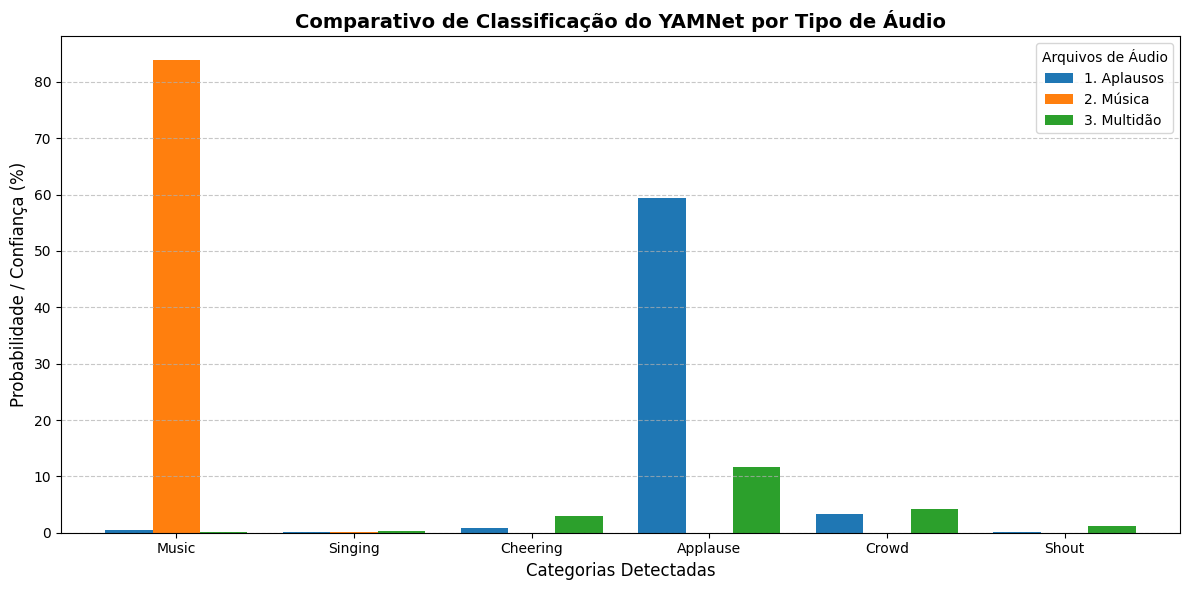

In [3]:
# ==============================================================================
# PASSO 1: Importar as bibliotecas necessárias
# ==============================================================================
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import tensorflow as tf
import tensorflow_hub as hub

print("✓ Bibliotecas importadas com sucesso!")

# ==============================================================================
# PASSO 2: Carregar o modelo YAMNet e o mapeamento das 521 classes
# ==============================================================================
print("Carregando o modelo YAMNet do TensorFlow Hub...")
yamnet_model = hub.load('https://tfhub.dev/google/yamnet/1')

# Extrair o mapa de classes do ativo do modelo
class_map_path = yamnet_model.class_map_path().numpy().decode('utf-8')
class_names = []
with open(class_map_path) as f:
    reader = csv.DictReader(f)
    for row in reader:
        class_names.append(row['display_name'])

print(f"✓ Modelo YAMNet carregado com {len(class_names)} classes registradas!\n")

# ==============================================================================
# PASSO 3: Mapear os arquivos de áudio e categorias de interesse
# O YAMNet exige estritamente áudio em MONO e Amostragem de 16.000 Hz (16kHz).
# ==============================================================================
audio_files = {
    '1. Aplausos': 'Applause.mp3',
    '2. Música': 'Music.mp3',
    '3. Multidão': 'crowd.mp3'
}

categories_to_check = ['Music', 'Singing', 'Cheering', 'Applause', 'Crowd', 'Shout']

results = {}

# ==============================================================================
# PASSO 4: Loop de Processamento com YAMNet
# ==============================================================================
print("Analisando os 3 áudios com YAMNet...\n")

for label, file_name in audio_files.items():
    print(f"Processando: {file_name} ({label})")

    # 1. Carregar áudio e reamostrar estritamente para 16kHz e Mono
    waveform, sr = librosa.load(file_name, sr=16000, mono=True)

    # 2. Executar a inferência no YAMNet
    scores, embeddings, spectrogram = yamnet_model(waveform)
    scores_np = scores.numpy()

    # 3. Média das probabilidades ao longo das janelas temporais do áudio
    mean_scores = np.mean(scores_np, axis=0)

    # 4. Extrair a pontuação (%) das categorias selecionadas
    file_scores = {}
    for cat in categories_to_check:
        if cat in class_names:
            idx = class_names.index(cat)
            file_scores[cat] = mean_scores[idx] * 100  # Converter para porcentagem
        else:
            file_scores[cat] = 0.0

    results[label] = file_scores

# ==============================================================================
# PASSO 5: Tabela Comparativa (Pandas)
# ==============================================================================
df_results = pd.DataFrame(results)

print("\n" + "="*60)
print("          TABELA COMPARATIVA DE RESULTADOS (%)          ")
print("="*60)
display(df_results.round(2))
print("="*60 + "\n")

# ==============================================================================
# PASSO 6: Gráfico Comparativo (Matplotlib)
# ==============================================================================
plt.figure(figsize=(12, 6))
ax = df_results.plot(kind='bar', figsize=(12, 6), width=0.8)

plt.title('Comparativo de Classificação do YAMNet por Tipo de Áudio', fontsize=14, fontweight='bold')
plt.ylabel('Probabilidade / Confiança (%)', fontsize=12)
plt.xlabel('Categorias Detectadas', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Arquivos de Áudio', fontsize=10)
plt.tight_layout()

# Exibir o gráfico diretamente no console do Colab
plt.show()

<a id="secao-2"></a>
## 2. Mão na Massa 2: Janelamento Deslizante (Sliding Window) & Smoothing

In [4]:
# ==============================================================================
# MÃO NA MASSA 2: Janelamento Deslizante (Sliding Window), Overlap & Smoothing
# ==============================================================================
import csv
import numpy as np
import librosa
import pandas as pd
from collections import deque
import tensorflow as tf
import tensorflow_hub as hub

# ------------------------------------------------------------------------------
# PASSO 1: Carregar o Modelo YAMNet e Mapear Palavras-Chave do Projeto
# ------------------------------------------------------------------------------
print("Carregando o modelo YAMNet...")
yamnet_model = hub.load('https://tfhub.dev/google/yamnet/1')

class_map_path = yamnet_model.class_map_path().numpy().decode('utf-8')
class_names = []
with open(class_map_path) as f:
    reader = csv.DictReader(f)
    for row in reader:
        class_names.append(row['display_name'])

# Função auxiliar para buscar os índices das palavras-chave no AudioSet
def get_class_indices(keywords):
    indices = []
    for i, name in enumerate(class_names):
        if any(kw.lower() in name.lower() for kw in keywords):
            indices.append(i)
    return indices

# Agrupando os índices por categoria de evento do show
cheering_idx = get_class_indices(["cheer", "applause", "yell", "shout", "crowd"])
coro_idx = get_class_indices(["singing", "choir", "crowd + singing"])
hubbub_idx = get_class_indices(["hubbub"])
music_idx = get_class_indices(["music", "guitar", "piano", "drum"])
interaction_idx = get_class_indices(["speech", "conversation", "laughter"])

# ------------------------------------------------------------------------------
# PASSO 2: Carregar o Áudio e Configurar o Janelamento (16kHz / Mono)
# ------------------------------------------------------------------------------
# Utilize um dos arquivos enviados (ex: crowd.mp3 ou o áudio longo do show)
audio_file = 'crowd.mp3'

print(f"Carregando e ajustando áudio: {audio_file}...")
waveform, sr = librosa.load(audio_file, sr=16000, mono=True)

# Parâmetros Oficiais de Janelamento:
# • Janela (CHUNK): 0.975s = 15.600 amostras a 16kHz
# • Passo (HOP): 50% de Overlap = 7.800 amostras (~0.487s)
chunk_samples = int(16000 * 0.975)
hop_samples = chunk_samples // 2

# Histórico para a Média Móvel (Smoothing) de ~2.5 segundos (5 janelas)
history = deque(maxlen=5)
chunk_results = []

print("Processando janelas temporais com Overlap e Média Móvel...\n")

# ------------------------------------------------------------------------------
# PASSO 3: Loop do Sliding Window
# ------------------------------------------------------------------------------
for start in range(0, len(waveform) - chunk_samples, hop_samples):
    # Fatiamento do bloco atual
    chunk = waveform[start : start + chunk_samples]
    time_offset = start / sr  # Início da janela em segundos

    # 1. Inferência na fatia atual do áudio
    scores, _, _ = yamnet_model(chunk)
    mean_scores = np.mean(scores.numpy(), axis=0)

    # 2. Extração das métricas brutas da janela
    raw_metrics = {
        "cheering": float(np.sum(mean_scores[cheering_idx])),
        "coro": float(np.sum(mean_scores[coro_idx])),
        "hubbub": float(np.sum(mean_scores[hubbub_idx])),
        "music": float(np.sum(mean_scores[music_idx])),
        "interaction": float(np.sum(mean_scores[interaction_idx]))
    }

    # 3. Média Móvel (Smoothing) usando o deque
    history.append(raw_metrics)
    avg_coro = float(np.mean([x["coro"] for x in history]))
    avg_cheer = float(np.mean([x["cheering"] for x in history]))
    avg_music = float(np.mean([x["music"] for x in history]))
    avg_inter = float(np.mean([x["interaction"] for x in history]))

    # 4. Proporção Música vs Interação (Ratio)
    total_mi = avg_music + avg_inter
    ratio = float(avg_music / total_mi if total_mi > 0 else 0.5)

    # 5. Gatilhos de Negócio / Regras de Decisão Automáticas
    evento = "Normal"
    if ratio < 0.6 and avg_coro > 0.3:
        evento = "Coro da Plateia"
    elif avg_cheer > 0.35:
        evento = "Explosão / Aplauso"

    chunk_results.append({
        "Tempo (s)": round(time_offset, 2),
        "Música (%)": round(avg_music * 100, 2),
        "Coro (%)": round(avg_coro * 100, 2),
        "Torcida (%)": round(avg_cheer * 100, 2),
        "Ratio (Múl/Inter)": round(ratio, 2),
        "Evento Detectado": evento
    })

# ------------------------------------------------------------------------------
# PASSO 4: Exibição da Tabela em Tempo Real
# ------------------------------------------------------------------------------
df_chunks = pd.DataFrame(chunk_results)

print("="*75)
print("          PROCESSAMENTO EM TEMPO REAL (JANELA A JANELA)          ")
print("="*75)
display(df_chunks.head(15)) # Exibe os primeiros 15 blocos temporais

Carregando o modelo YAMNet...
Carregando e ajustando áudio: crowd.mp3...
Processando janelas temporais com Overlap e Média Móvel...

          PROCESSAMENTO EM TEMPO REAL (JANELA A JANELA)          


,Tempo (s),Música (%),Coro (%),Torcida (%),Ratio (Múl/Inter),Evento Detectado
0,0.00,2.16,2.28,49.36,0.09,Explosão / Aplauso
1,0.49,1.09,1.14,25.40,0.02,Normal
2,0.97,0.91,0.78,24.02,0.02,Normal
3,1.46,0.74,0.60,24.35,0.02,Normal
4,1.95,0.60,0.48,20.92,0.01,Normal
5,2.44,0.19,0.05,13.44,0.00,Normal
6,2.92,0.26,0.07,26.91,0.01,Normal
7,3.41,0.28,0.08,42.86,0.01,Explosão / Aplauso
8,3.90,0.27,0.07,56.01,0.02,Explosão / Aplauso
9,4.39,0.42,0.10,71.99,0.05,Explosão / Aplauso


<a id="secao-3"></a>
## 3. Mão na Massa 3: Análise Temporal do Show (Linha do Tempo e Gráficos)

Carregando o modelo YAMNet...
Carregando o áudio completo do show: Show.mp3...
Processando a linha do tempo e métricas de áudio do show...



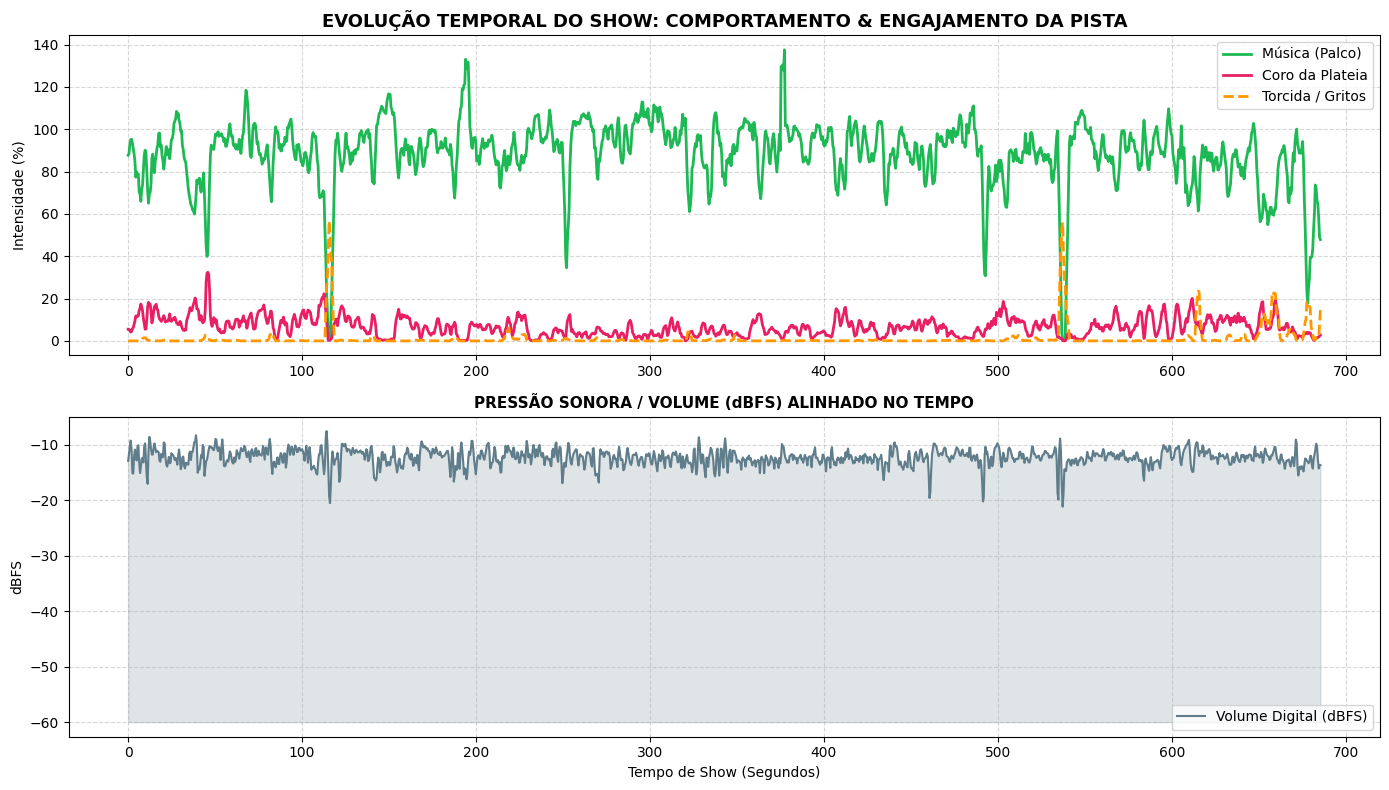

In [6]:
# ==============================================================================
# MÃO NA MASSA 3: Linha do Tempo Completa do Show & Gráficos de Engajamento
# ==============================================================================
import csv
import numpy as np
import librosa
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
import tensorflow as tf
import tensorflow_hub as hub

# ------------------------------------------------------------------------------
# PASSO 1: Carregar o Modelo e Mapear Índices
# ------------------------------------------------------------------------------
print("Carregando o modelo YAMNet...")
yamnet_model = hub.load('https://tfhub.dev/google/yamnet/1')

class_map_path = yamnet_model.class_map_path().numpy().decode('utf-8')
class_names = []
with open(class_map_path) as f:
    reader = csv.DictReader(f)
    for row in reader:
        class_names.append(row['display_name'])

def get_class_indices(keywords):
    indices = []
    for i, name in enumerate(class_names):
        if any(kw.lower() in name.lower() for kw in keywords):
            indices.append(i)
    return indices

cheering_idx = get_class_indices(["cheer", "applause", "yell", "shout", "crowd"])
coro_idx = get_class_indices(["singing", "choir", "crowd + singing"])
hubbub_idx = get_class_indices(["hubbub"])
music_idx = get_class_indices(["music", "guitar", "piano", "drum"])
interaction_idx = get_class_indices(["speech", "conversation", "laughter"])

# ------------------------------------------------------------------------------
# PASSO 2: Processamento Temporal Completo (YAMNet + DSP: RMS e dBFS)
# ------------------------------------------------------------------------------
audio_file = 'Show.mp3'

print(f"Carregando o áudio completo do show: {audio_file}...")
waveform, sr = librosa.load(audio_file, sr=16000, mono=True)

# Janelamento oficial: 0.975s com 50% de Overlap (0.487s)
chunk_samples = int(16000 * 0.975)
hop_samples = chunk_samples // 2

history = deque(maxlen=5) # Moving Average de 5 janelas (~2.5s)
timeline_data = []
last_rms = 0.0

print("Processando a linha do tempo e métricas de áudio do show...\n")

for start in range(0, len(waveform) - chunk_samples, hop_samples):
    chunk = waveform[start : start + chunk_samples]
    time_offset = start / sr # Offset em segundos

    # 1. DSP: Cálculo de RMS (Energia) e dBFS (Volume Logarítmico)
    rms = float(np.sqrt(np.mean(np.square(chunk))))
    dbfs = float(20 * np.log10(max(rms, 1e-5))) # Proteção contra log(0)

    # Detecção de Onset (Ataque Sonoro / Pico Brusco)
    onset_spike = (rms - last_rms) > 0.05
    last_rms = rms

    # 2. IA: Inferência do YAMNet
    scores, _, _ = yamnet_model(chunk)
    mean_scores = np.mean(scores.numpy(), axis=0)

    raw_metrics = {
        "cheering": float(np.sum(mean_scores[cheering_idx])),
        "coro": float(np.sum(mean_scores[coro_idx])),
        "hubbub": float(np.sum(mean_scores[hubbub_idx])),
        "music": float(np.sum(mean_scores[music_idx])),
        "interaction": float(np.sum(mean_scores[interaction_idx]))
    }

    # 3. Suavização (Moving Average)
    history.append(raw_metrics)
    avg_coro = float(np.mean([x["coro"] for x in history]))
    avg_cheer = float(np.mean([x["cheering"] for x in history]))
    avg_music = float(np.mean([x["music"] for x in history]))
    avg_inter = float(np.mean([x["interaction"] for x in history]))
    avg_hubbub = float(np.mean([x["hubbub"] for x in history]))

    # Proporção de Música vs Interação
    total_mi = avg_music + avg_inter
    ratio = float(avg_music / total_mi if total_mi > 0 else 0.5)

    # 4. Regras de Decisão / Eventos Automáticos
    evento = "Normal"
    if ratio < 0.6 and avg_coro > 0.3:
        evento = "Coro da Plateia"
    elif onset_spike and avg_cheer > 0.3:
        evento = "Explosão / Transição"
    elif avg_hubbub > 0.2 and avg_music < 0.2:
        evento = "Intervalo / Fala"

    timeline_data.append({
        "Tempo (s)": round(time_offset, 2),
        "RMS": round(rms, 4),
        "dBFS": round(dbfs, 2),
        "Música (%)": round(avg_music * 100, 2),
        "Coro (%)": round(avg_coro * 100, 2),
        "Torcida (%)": round(avg_cheer * 100, 2),
        "Burburinho (%)": round(avg_hubbub * 100, 2),
        "Evento Detectado": evento
    })

# Converter em DataFrame
df_timeline = pd.DataFrame(timeline_data)

# ------------------------------------------------------------------------------
# PASSO 3: Geração dos Gráficos Duplos de Linha do Tempo
# ------------------------------------------------------------------------------
plt.figure(figsize=(14, 8))

# Subplot 1: Comportamento do Público (Música vs Coro vs Torcida)
plt.subplot(2, 1, 1)
plt.plot(df_timeline["Tempo (s)"], df_timeline["Música (%)"], label="Música (Palco)", color="#1DB954", linewidth=2)
plt.plot(df_timeline["Tempo (s)"], df_timeline["Coro (%)"], label="Coro da Plateia", color="#E91E63", linewidth=2)
plt.plot(df_timeline["Tempo (s)"], df_timeline["Torcida (%)"], label="Torcida / Gritos", color="#FF9800", linewidth=2, linestyle="--")
plt.title("EVOLUÇÃO TEMPORAL DO SHOW: COMPORTAMENTO & ENGAJAMENTO DA PISTA", fontsize=13, fontweight='bold')
plt.ylabel("Intensidade (%)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right")

# Subplot 2: Pressão Sonora em dBFS (Volume Alinhado no Tempo)
plt.subplot(2, 1, 2)
plt.plot(df_timeline["Tempo (s)"], df_timeline["dBFS"], label="Volume Digital (dBFS)", color="#607D8B", linewidth=1.5)
plt.fill_between(df_timeline["Tempo (s)"], df_timeline["dBFS"], -60, color="#607D8B", alpha=0.2)
plt.title("PRESSÃO SONORA / VOLUME (dBFS) ALINHADO NO TEMPO", fontsize=11, fontweight='bold')
plt.xlabel("Tempo de Show (Segundos)")
plt.ylabel("dBFS")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()